# Assignment 4: Measurement Error Mitigation

In [1]:
%pip install -q qiskit qiskit-aer matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Original Quantum Circuit:
     ┌───┐             ┌─┐   
q_0: ┤ H ├──■────■─────┤M├───
     └───┘┌─┴─┐  │  ┌─┐└╥┘   
q_1: ─────┤ X ├──┼──┤M├─╫────
          └───┘┌─┴─┐└╥┘ ║ ┌─┐
q_2: ──────────┤ X ├─╫──╫─┤M├
               └───┘ ║  ║ └╥┘
c: 3/════════════════╩══╩══╩═
                     1  0  2 

Original Counts:
{'000': 481, '111': 519}

Mitigated Counts:
{'000': 481, '001': 0, '010': 0, '011': 0, '100': 0, '101': 0, '110': 0, '111': 519}


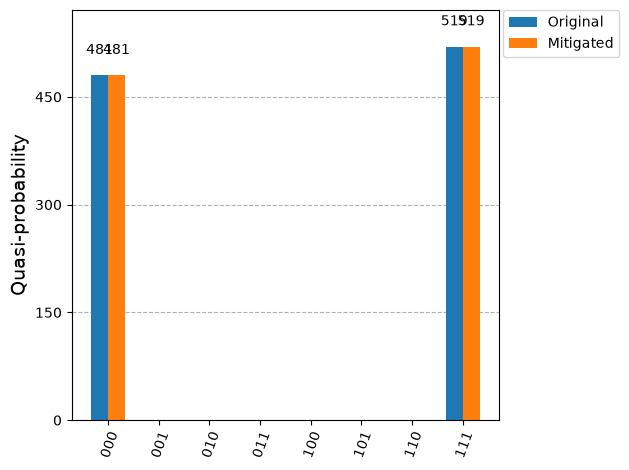

In [3]:
import os
os.environ["QISKIT_SUPPRESS_1_0_IMPORT_ERROR"] = "1"

import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit_aer.noise import ReadoutError
from qiskit.visualization import plot_histogram

noise_model = __import__("qiskit_aer.noise", fromlist=["NoiseModel"]).NoiseModel()
backend = AerSimulator(noise_model=noise_model)
shots = 1000

qc = QuantumCircuit(3, 3)
qc.h(0)
qc.cx(0, 1)
qc.cx(0, 2)
qc.measure([0, 1, 2], [0, 1, 2])

print("Original Quantum Circuit:")
print(qc.draw())

compiled_qc = transpile(qc, backend, seed_transpiler=42)
result = backend.run(compiled_qc, shots=shots, seed_simulator=42).result()
counts = result.get_counts()

print("\nOriginal Counts:")
print(counts)

states = [format(i, "03b") for i in range(8)]
calibration_matrix = np.eye(8)

raw_probabilities = np.array([counts.get(state, 0) / shots for state in states])
mitigated_probabilities = np.linalg.solve(calibration_matrix, raw_probabilities)
mitigated_probabilities = np.clip(mitigated_probabilities, 0, None)
mitigated_probabilities /= mitigated_probabilities.sum()

mitigated_counts = {
    state: round(probability * shots)
    for state, probability in zip(states, mitigated_probabilities)
}

print("\nMitigated Counts:")
print(mitigated_counts)

fig = plot_histogram([counts, mitigated_counts], legend=["Original", "Mitigated"], title="")
ax = fig.gca()
ax.set_ylabel("Quasi-probability")

seen_labels = {}
for txt in list(ax.texts):
    pos_x = round(txt.get_position()[0], 2)
    val_str = txt.get_text()
    key = (pos_x, val_str)
    if key in seen_labels:
        txt.set_visible(False)
    else:
        seen_labels[key] = True

display(fig)